In [1]:
!pip install -q kagglehub timm

In [2]:
import kagglehub
import os

path = kagglehub.dataset_download("faysalmiah1721758/potato-dataset")
print("Dataset path:", path)
print("Files and folders:", os.listdir(path))

Using Colab cache for faster access to the 'potato-dataset' dataset.
Dataset path: /kaggle/input/potato-dataset
Files and folders: ['Potato___healthy', 'Potato___Late_blight', 'Potato___Early_blight']


In [3]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# val_transform: same resize + normalize, but NO augmentation
# (augmentation is only for training; validation/test must see the real, unmodified image)
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Using device: cuda


Total images found: 2152


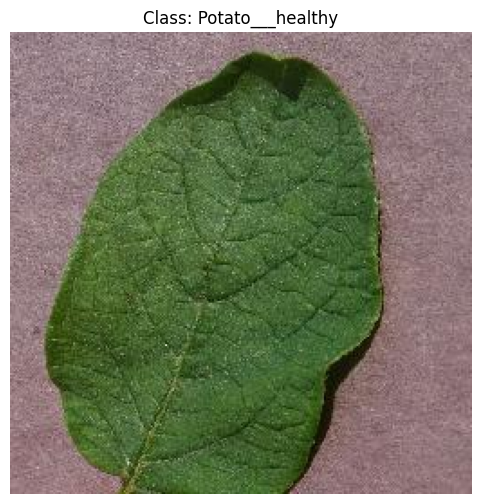

In [4]:
import os
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import random

path_obj = Path(path)
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
image_files = [f for f in path_obj.rglob("*") if f.is_file() and f.suffix.lower() in image_extensions]

print("Total images found:", len(image_files))

if image_files:
    image_path = random.choice(image_files)
    image = Image.open(image_path).convert("RGB")
    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.title(f"Class: {image_path.parent.name}")
    plt.axis("off")
    plt.show()

In [5]:
from pathlib import Path

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def is_class_directory(folder):
    subfolders = [p for p in folder.iterdir() if p.is_dir()]
    return (
        len(subfolders) >= 2
        and all(
            any(f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS for f in subfolder.rglob("*"))
            for subfolder in subfolders
        )
    )

root = Path(path)
candidates = [folder for folder in [root, *root.rglob("*")] if folder.is_dir() and is_class_directory(folder)]

# the shallowest matching folder is the real class-folder root
dataset_root = min(candidates, key=lambda p: len(p.parts))
print("Using dataset root:", dataset_root)
print("Classes found:", [p.name for p in dataset_root.iterdir() if p.is_dir()])

Using dataset root: /kaggle/input/potato-dataset
Classes found: ['Potato___healthy', 'Potato___Late_blight', 'Potato___Early_blight']


## Loading the dataset + train/val splitThis part was missing from the original notebook — `full_dataset`, `train_loader` and `val_loader` were used later but never created.

In [6]:
full_dataset = datasets.ImageFolder(root=dataset_root, transform=train_transform)

val_size = int(0.2 * len(full_dataset))
train_size = len(full_dataset) - val_size
train_subset, val_subset = random_split(full_dataset, [train_size, val_size])

# the val subset must use val_transform (no augmentation) -- random_split shares the
# underlying dataset object, so we wrap it to apply a different transform
val_subset.dataset.transform = train_transform  # placeholder, fixed below with a wrapper

class TransformWrapper(torch.utils.data.Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform
    def __len__(self):
        return len(self.subset)
    def __getitem__(self, idx):
        img, label = self.subset.dataset.samples[self.subset.indices[idx]]
        image = Image.open(img).convert("RGB")
        return self.transform(image), label

val_dataset = TransformWrapper(val_subset, val_transform)

train_loader = DataLoader(train_subset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

print("Train size:", train_size, " Val size:", val_size)
print("Classes:", full_dataset.classes)

Train size: 1722  Val size: 430
Classes: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']


In [7]:
import timm

num_classes = len(full_dataset.classes)

model = timm.create_model("vit_base_patch16_224", pretrained=True, num_classes=num_classes)
model = model.to(device)

print(model.__class__.__name__)
print("Output classes:", num_classes)

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

VisionTransformer
Output classes: 3


In [8]:
images, labels = next(iter(train_loader))
images = images.to(device)
labels = labels.to(device)

model.eval()
with torch.no_grad():
    outputs = model(images)

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Model output shape:", outputs.shape)
print("Class names:", full_dataset.classes)

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Model output shape: torch.Size([32, 3])
Class names: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']


In [9]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

EPOCHS = 5
history = {"train_acc": [], "val_acc": [], "train_loss": [], "val_loss": []}

for epoch in range(EPOCHS):
    # ---- training ----
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # ---- validation ----
    model.eval()
    val_running_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            val_correct += (predicted == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_acc = val_correct / val_total

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(f"Epoch {epoch+1}/{EPOCHS} - "
          f"train_loss: {train_loss:.4f}, train_acc: {train_acc:.4f}, "
          f"val_loss: {val_loss:.4f}, val_acc: {val_acc:.4f}")

Epoch 1/5 - train_loss: 0.5444, train_acc: 0.8002, val_loss: 0.8419, val_acc: 0.6814
Epoch 2/5 - train_loss: 0.0806, train_acc: 0.9733, val_loss: 0.0025, val_acc: 1.0000
Epoch 3/5 - train_loss: 0.0765, train_acc: 0.9774, val_loss: 0.0170, val_acc: 0.9953
Epoch 4/5 - train_loss: 0.0243, train_acc: 0.9925, val_loss: 0.0043, val_acc: 1.0000
Epoch 5/5 - train_loss: 0.0073, train_acc: 0.9983, val_loss: 0.0011, val_acc: 1.0000


In [10]:
print("Final Training Accuracy :", round(history["train_acc"][-1]*100, 2), "%")
print("Final Validation Accuracy:", round(history["val_acc"][-1]*100, 2), "%")

Final Training Accuracy : 99.83 %
Final Validation Accuracy: 100.0 %


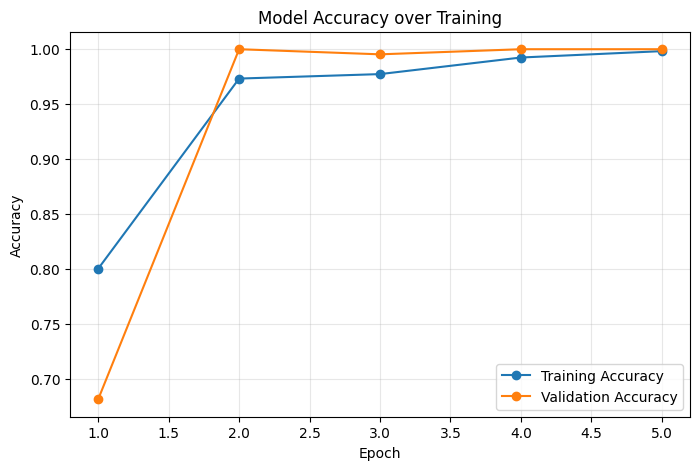

In [11]:
plt.figure(figsize=(8,5))
plt.plot(range(1, EPOCHS+1), history["train_acc"], marker='o', label="Training Accuracy")
plt.plot(range(1, EPOCHS+1), history["val_acc"], marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model Accuracy over Training")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

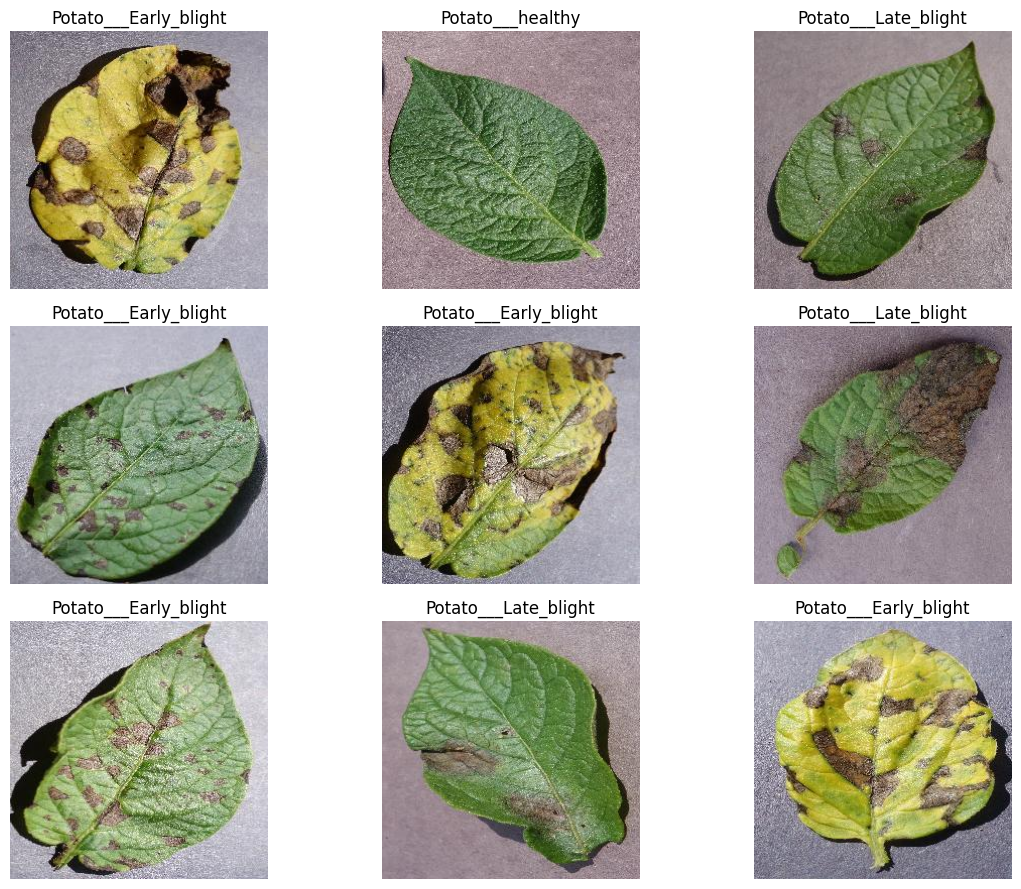

In [12]:
import matplotlib.pyplot as plt
import random
from PIL import Image

sample_images = random.sample(image_files, min(9, len(image_files)))
plt.figure(figsize=(12, 9))
for i, image_path in enumerate(sample_images):
    image = Image.open(image_path).convert("RGB")
    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(image_path.parent.name)
    plt.axis("off")
plt.tight_layout()
plt.show()

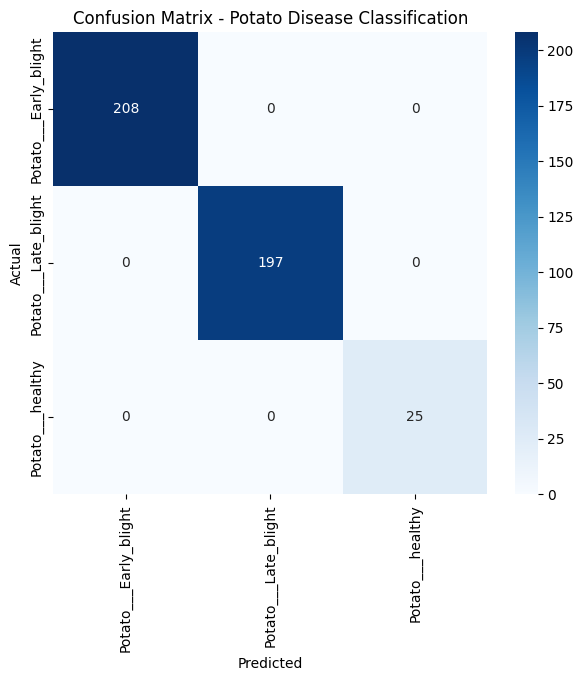

                       precision    recall  f1-score   support

Potato___Early_blight       1.00      1.00      1.00       208
 Potato___Late_blight       1.00      1.00      1.00       197
     Potato___healthy       1.00      1.00      1.00        25

             accuracy                           1.00       430
            macro avg       1.00      1.00      1.00       430
         weighted avg       1.00      1.00      1.00       430



In [13]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import numpy as np

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=full_dataset.classes,
            yticklabels=full_dataset.classes)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Potato Disease Classification")
plt.show()

print(classification_report(all_labels, all_preds, target_names=full_dataset.classes))

In [14]:
import torch

torch.save({
    "model_state_dict": model.state_dict(),
    "classes": full_dataset.classes,
}, "potato_vit.pth")

import os
print("Saved! Size:", round(os.path.getsize("potato_vit.pth") / (1024*1024), 1), "MB")

Saved! Size: 327.4 MB


In [15]:
from google.colab import files
files.download("potato_vit.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>